# Mechanics 4: Gravity and orbits

*Learning path: mechanics, part 4 of 7.* [Index](README.md) · Previous: [Rotation](03-rotation.ipynb) · Next: [Lagrangian mechanics](05-lagrangian-mechanics.ipynb)

Around 1610 Kepler, after years with Tycho Brahe's measurements of Mars, found three rules for the planets: they move
on ellipses with the Sun at one focus, they sweep out equal areas in equal times, and the square of the period is
proportional to the cube of the orbit's size. He had no idea why. In 1687 Newton showed that all three follow from one
law, a force $F = GMm/r^2$ pulling towards the Sun. This lesson derives Kepler's laws from that force, plans trips
between orbits, and then meets the three-body problem, where formulas give out and numerics take over.

**Who this is for.** You have done [lesson 3](03-rotation.ipynb).

**What you will be able to do afterwards:**

1. compute orbital speeds and periods, and the height of a geostationary orbit;
2. solve the motion under $1/r^2$ gravity numerically and check Kepler's laws on the result;
3. plan a Hohmann transfer between two circular orbits;
4. simulate three bodies and recognise sensitive dependence on starting conditions.

Plan about two hours.

## 1. Circular orbits

For a circular orbit of radius $r$, gravity supplies exactly the force needed to bend the path:
$GMm/r^2 = mv^2/r$, so $v = \sqrt{GM/r}$, and one orbit takes $T = 2\pi r/v = 2\pi\sqrt{r^3/GM}$. The International
Space Station flies about 400 km up:

In [1]:
GM = const.G*const.Mearth;
r = const.Rearth + 400 km;
eval(convert(sqrt(GM/r), km/s), 3)
eval(convert(2*pi*sqrt(r^3/GM), min), 3)

7.67 km/s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

92.4 min

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

7.67 km/s, around the Earth in an hour and a half. A **geostationary** satellite takes exactly one sidereal day
(86 164 s) per orbit, so it hangs above one spot on the equator. Solving $T = 2\pi\sqrt{r^3/GM}$ for $r$:

In [2]:
eval(convert((GM*(86164 s)^2/(4*pi^2))^(1/3), km), 4)

4.216e4 km

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

42 160 km from the Earth's centre, about 35 800 km up. That is where TV satellites sit.

**Try this.** The Moon is 384 400 km away. What period does the formula give? (The real sidereal month is 27.3 days.)

## 2. Kepler's laws from Newton's force

Now let the orbit be anything. In units where $GM = 1$, the force per unit mass is $-r/|r|^3$, so with velocity
$(v_x, v_y)$ the equations of motion are four first-order equations. Start at distance 1 with speed 1.2 (a circle would
need speed 1):

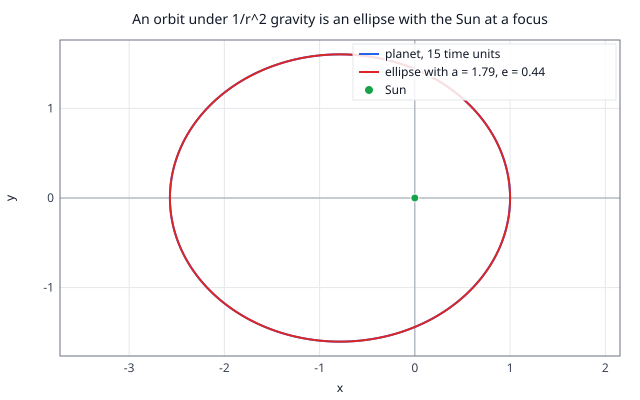

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
f = [vx, vy, -x/(x^2 + y^2)^(3/2), -y/(x^2 + y^2)^(3/2)];
p = odeplot(f, [x y vx vy], t, [1, 0, 0, 1.2], 0, 15, [x y]);
a0 = 1/0.56;
e0 = 1 - 1/a0;
p = show(p, parametric(a0*(cos(q) - e0), a0*sqrt(1 - e0^2)*sin(q), q, 0, 2*pi));
p = show(p, scatter([0], [0]));
p = legend(p, "planet, 15 time units", "ellipse with a = 1.79, e = 0.44", "Sun");
labels(title(p, "An orbit under 1/r^2 gravity is an ellipse with the Sun at a focus"), "x", "y")

An ellipse, closing on itself, with the Sun at one focus, not the centre: **Kepler's first law**. The numerical orbit
lies exactly on the ellipse with semi-major axis $a = 1.79$ and eccentricity $e = 0.44$ (where those numbers come
from is the third law below). Exercise 4 proves the first law in general.

**The second law** says the line from the Sun sweeps equal areas in equal times. In time $dt$ it sweeps a thin triangle
of area $\tfrac12|r\times v|\,dt$, so the law says $h = xv_y - yv_x$ is constant. That $h$ is the angular momentum per
unit mass, and it is conserved because the force points straight at the Sun: its torque about the Sun is zero (lesson
3). Check it, and the energy $E = \tfrac12v^2 - 1/r$, along the numerical orbit:

In [4]:
D = odedata(f, [x y vx vy], t, [1, 0, 0, 1.2], 0, 10, 1000);
h(k) := D(k, 2)*D(k, 5) - D(k, 3)*D(k, 4);
E(k) := (D(k, 4)^2 + D(k, 5)^2)/2 - 1/sqrt(D(k, 2)^2 + D(k, 3)^2);
eval([h(1), h(300), h(700), h(1001)], 6)
eval([E(1), E(300), E(700), E(1001)], 6)

[1.20000, 1.20000, 1.20000, 1.20000]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

[-0.280000, -0.280000, -0.280000, -0.280000]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**The third law.** For an ellipse with semi-major axis $a$ the energy is $E = -GM/(2a)$, and the period is
$T = 2\pi\sqrt{a^3/GM}$, the same as for a circle of radius $a$. Here:

In [5]:
a = -1/(2*E(1));
eval(a, 4)
eval(2*pi*a^(3/2), 4)

1.786

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

14.99

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

A period of 15.0, which is why the plot above, run for 15 time units, closes exactly once. Kepler checked the law on
the six planets he knew. With $T$ in years and $a$ in astronomical units, $T^2/a^3$ should be 1:

In [6]:
T = [0.241, 0.615, 1, 1.881, 11.86, 29.46];
A = [0.387, 0.723, 1, 1.524, 5.203, 9.537];
eval(T.^2 ./ A.^3, 3)
linfit(log(A), log(T))

[1.00, 1.00, 1.00, 1.00, 0.999, 1.00]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.4997134333058495*x+0.0002795617571564879

> Least-squares line: slope b = Sxy/Sxx = 1.4997134333058495, intercept a = mean(y) − b·mean(x) = 0.0002795617571564879. It minimizes the sum of squared vertical distances. r² = 0.9999999351997525: the fraction of the variance of y that the line explains.

On a log-log scale the points lie on a line of slope 1.50: $T \propto a^{3/2}$.

**Try this.** Halley's comet returns every 76 years. What is the semi-major axis of its orbit?

## 3. Moving between orbits

To raise a satellite from a low orbit (radius $r_1$) to a high one ($r_2$), the cheapest two-burn route is the
**Hohmann transfer**: one burn puts it on an ellipse that touches both circles, half an ellipse later a second burn
makes the orbit circular again. On an ellipse with semi-major axis $a$ the speed at distance $r$ is
$v = \sqrt{GM(2/r - 1/a)}$ (the *vis-viva* equation, from energy conservation). From 300 km up to geostationary:

In [7]:
r1 = const.Rearth + 300 km;
r2 = 42164 km;
a = (r1 + r2)/2;
dv1 = sqrt(GM*(2/r1 - 1/a)) - sqrt(GM/r1);
dv2 = sqrt(GM/r2) - sqrt(GM*(2/r2 - 1/a));
eval(convert(dv1, km/s), 3)
eval(convert(dv2, km/s), 3)
eval(convert(pi*sqrt(a^3/GM), h), 3)

2.43 km/s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.47 km/s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

5.27 h

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

3.9 km/s in total, and five and a quarter hours of coasting. The same plan takes a probe from the Earth's orbit to Mars
(1.524 AU), now around the Sun:

In [8]:
am = (1 AU + 1.524 AU)/2;
eval(convert(pi*sqrt(am^3/(const.G*const.Msun)), day), 4)

258.9 day

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

About 259 days, close to what real Mars missions take. The transfer orbit has the Sun at its focus and touches the
Earth's orbit at its near end and Mars's at its far end. The launch must be timed so that Mars arrives at the far end
at the same moment, which happens once every 26 months: the launch windows.

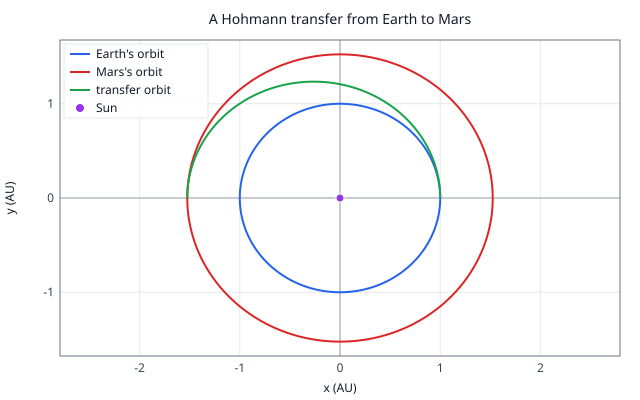

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
e = (1.524 - 1)/(1.524 + 1);
p = parametric(cos(q), sin(q), q, 0, 2*pi);
p = show(p, parametric(1.524*cos(q), 1.524*sin(q), q, 0, 2*pi));
p = show(p, parametric(cos(q)/(1 + e*cos(q))*(1 + e), sin(q)/(1 + e*cos(q))*(1 + e), q, 0, pi));
p = show(p, scatter([0], [0]));
p = legend(p, "Earth's orbit", "Mars's orbit", "transfer orbit", "Sun");
labels(title(p, "A Hohmann transfer from Earth to Mars"), "x (AU)", "y (AU)")

**Try this.** How long does a Hohmann transfer to Jupiter (5.2 AU) take?

## 4. Three bodies

Two bodies give ellipses forever. Add a third and there is no general formula: Poincaré showed in the 1890s that the
motion can be **chaotic**. But numerics do not care. Three equal masses ($G = m = 1$), each pulled by the other two:

In [10]:
d12 = ((x1 - x2)^2 + (y1 - y2)^2)^(3/2);
d13 = ((x1 - x3)^2 + (y1 - y3)^2)^(3/2);
d23 = ((x2 - x3)^2 + (y2 - y3)^2)^(3/2);
f3 = [u1, w1, u2, w2, u3, w3, (x2 - x1)/d12 + (x3 - x1)/d13, (y2 - y1)/d12 + (y3 - y1)/d13, (x1 - x2)/d12 + (x3 - x2)/d23, (y1 - y2)/d12 + (y3 - y2)/d23, (x1 - x3)/d13 + (x2 - x3)/d23, (y1 - y3)/d13 + (y2 - y3)/d23];

In 1993 Cris Moore found, and in 2000 Chenciner and Montgomery proved, a remarkable orbit: all three bodies chase each
other along one figure eight. It needs very particular starting values:

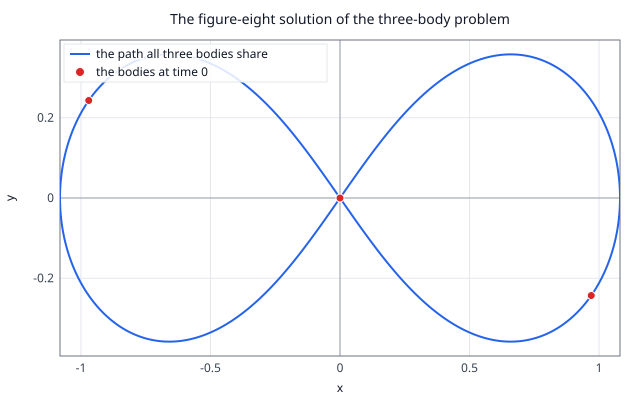

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [11]:
s0 = [0.97000436, -0.24308753, 0, 0, -0.97000436, 0.24308753, 0.466203685, 0.43236573, -0.93240737, -0.86473146, 0.466203685, 0.43236573];
p = odeplot(f3, [x1 y1 x2 y2 x3 y3 u1 w1 u2 w2 u3 w3], t, s0, 0, 6.326, [x1 y1]);
p = show(p, scatter([0.97000436, 0, -0.97000436], [-0.24308753, 0, 0.24308753]));
p = legend(p, "the path all three bodies share", "the bodies at time 0");
labels(title(p, "The figure-eight solution of the three-body problem"), "x", "y")

After one period, 6.326, body 1 is back where it started:

In [12]:
D3 = odedata(f3, [x1 y1 x2 y2 x3 y3 u1 w1 u2 w2 u3 w3], t, s0, 0, 6.326, 100);
eval([D3(101, 2), D3(101, 3)], 4)

[0.9700, -0.2431]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Most starting values are nothing like this. Put the middle body at rest, slightly off-centre, with the outer two moving
in opposite directions, and run two copies whose starting points differ by one part in a thousand:

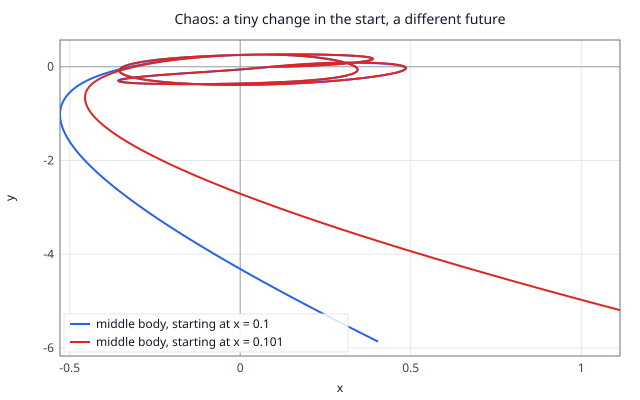

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [13]:
s1 = [1, 0, 0.1, 0, -1, 0, 0, 0.5, 0, 0, 0, -0.5];
s2 = [1, 0, 0.101, 0, -1, 0, 0, 0.5, 0, 0, 0, -0.5];
p = odeplot(f3, [x1 y1 x2 y2 x3 y3 u1 w1 u2 w2 u3 w3], t, s1, 0, 12, [x2 y2]);
p = show(p, odeplot(f3, [x1 y1 x2 y2 x3 y3 u1 w1 u2 w2 u3 w3], t, s2, 0, 12, [x2 y2]));
p = legend(p, "middle body, starting at x = 0.1", "middle body, starting at x = 0.101");
labels(title(p, "Chaos: a tiny change in the start, a different future"), "x", "y")

For a while the two paths agree; then they part, and in both runs the middle body is eventually flung out, but in
different directions. That is **sensitive dependence on initial
conditions**. It is why the long-term future of the Solar System can only be stated statistically: Laskar's
simulations give Mercury about a 1% chance of a collision course within the next five billion years.

**Try this.** Change the 0.101 to 0.1001. Do the paths stay together longer?

## Summary

* Circular orbits: $v = \sqrt{GM/r}$ and $T = 2\pi\sqrt{r^3/GM}$; geostationary orbits sit 35 800 km up.
* Newton's $1/r^2$ force gives all three of Kepler's laws: ellipses, equal areas (angular momentum conservation), and
  $T^2 \propto a^3$.
* The vis-viva equation $v^2 = GM(2/r - 1/a)$ plans transfers between orbits.
* Three bodies have no general formula; their motion can be chaotic, and numerics are the way in.

Next: [Lagrangian mechanics](05-lagrangian-mechanics.ipynb), a way to get equations of motion without drawing forces.

## Exercises

1. **Low orbit.** What is the period of an orbit just above the Earth's surface? Why can't any Earth satellite orbit
   faster?
2. **Weighing the Sun.** From the Earth's orbit (1 AU, one year), find $GM_\odot$ and then $M_\odot$. Compare with
   `const.Msun`.
3. **Escape.** Show that a speed of $\sqrt2$ in section 2 gives $E = 0$. Plot the orbit with speed 1.5 and describe it.
4. **First law.** In polar coordinates, with $u = 1/r$, the orbit equation is $u'' + u = GM/h^2$ (prime is
   $d/d\theta$). Solve it with `dsolve` and show that $r = 1/u$ is a conic section.
5. **Moon trip.** Estimate the time of a Hohmann transfer from low Earth orbit to the Moon's distance.
6. **Figure-eight energy.** Compute the total energy (kinetic minus the three $1/r_{ij}$ terms) of the figure-eight at
   time 0 and at the end, using `odedata`.

## Hints and answers

* **Section 1, Try this.** `eval(convert(2*pi*sqrt((384400 km)^3/GM), day), 3)` gives 27.4 days.
* **Section 2, Try this.** $a = 76^{2/3} \approx 17.9$ AU.
* **Section 3, Try this.** $a = 3.1$ AU, so half a period is $\tfrac12\cdot3.1^{3/2} \approx 2.7$ years.
* **Section 4, Try this.** Yes: each factor of ten in the start gives roughly a fixed extra stretch of time, the
  signature of exponential divergence.
* **Exercise 1.** About 84 minutes; a lower orbit would be inside the Earth.
* **Exercise 2.** $GM = 4\pi^2(1\,\mathrm{AU})^3/(1\,\mathrm{yr})^2$, giving $M \approx 1.99\cdot10^{30}$ kg.
* **Exercise 3.** $\tfrac12\cdot2 - 1 = 0$. With speed 1.5 the energy is positive and the orbit is a hyperbola: the
  planet leaves for good.
* **Exercise 4.** `dsolve(u'' + u == k, u, th)` gives $u = k + C_1\cos\theta + C_2\sin\theta$, so
  $r = 1/(k + C\cos(\theta - \theta_0))$: an ellipse, parabola or hyperbola.
* **Exercise 5.** $a \approx 195\,000$ km, so about 5 days. (Apollo, on a faster path, took 3.)
* **Exercise 6.** About $-1.287$, the same at both ends to many digits.

## Sources

1. J. Kepler, *Astronomia nova* (1609) and *Harmonices mundi* (1619).
2. I. Newton, *Philosophiæ naturalis principia mathematica* (1687), book I, propositions 11–17.
3. W. Hohmann, *Die Erreichbarkeit der Himmelskörper*, Oldenbourg (1925).
4. C. Moore, "Braids in classical dynamics", *Physical Review Letters* 70, 3675 (1993).
5. A. Chenciner and R. Montgomery, "A remarkable periodic solution of the three-body problem in the case of equal
   masses", *Annals of Mathematics* 152, 881–901 (2000).
6. J. Laskar and M. Gastineau, "Existence of collisional trajectories of Mercury, Mars and Venus with the Earth",
   *Nature* 459, 817–819 (2009).